# Task 18. FEM/FEniCS для уравнения Синус-Гордона

В качестве модели берем уравнение Синус-Гордона:

$$
    u_{tt} - c^2 \Delta u + \omega^2 \sin u = 0.
$$

Для первого варианта решения работаем в 1D на достаточно большом отрезке. Это удобно для проверки, потому что у задачи есть точное солитонное решение типа kink.

- из "Библиотека FEniCS": сначала переводим уравнение в слабую форму, затем выбираем конечномерное пространство, затем собираем и решаем систему;
- из примера Пуассона: старшую пространственную производную переносим на тестовую функцию интегрированием по частям;
- из примера теплопроводности: время дискретизуем вручную, а на каждом шаге решаем пространственную FEM-задачу;
- из примера нелинейного Пуассона: нелинейность решаем итерационно, здесь через Newton solver FEniCS.

## План

1. Зафиксировать математическую постановку: область, граничные/начальные условия, точное kink-решение для проверки.
2. Выписать слабую форму и неявную схему по времени, чтобы получить нелинейную задачу на каждом временном слое.
3. Реализовать расчет во FEniCS: сетка, пространство `Lagrange P1`, начальные условия, граничные условия, Newton solver.
4. Посчитать ошибки: $L_2$-ошибка относительно точного решения и сохранение энергии.
5. Исследовать сходимость по пространству: прогнать несколько сеток и построить log-log график ошибки от $h$.
6. Описать проблемы: влияние границ, смешивание ошибок по времени и пространству, сложность резкого фронта при $v \to 1$.


## 1. Постановка и точное решение

Берем нормированное уравнение при $c=1$, $\omega=1$ на отрезке $\Omega=[x_L,x_R]$:

$$
    u_{tt} - u_{xx} + \sin u = 0.
$$

Точное решение-kink на бесконечной прямой:

$$
    u_{\text{exact}}(x,t) = 4\arctan\left(\exp\left(\frac{x-x_0-vt}{\sqrt{1-v^2}}\right)\right), \quad |v|<1.
$$

На конечном отрезке задаем граничные условия Дирихле из точного решения:

$$
    u(x_L,t)=u_{\text{exact}}(x_L,t), \quad
    u(x_R,t)=u_{\text{exact}}(x_R,t).
$$

Начальные условия для двухшаговой схемы удобно задать как значения точного решения в моменты $t=-\Delta t$ и $t=0$:

$$
    u^{-1}(x)=u_{\text{exact}}(x,-\Delta t), \quad
    u^{0}(x)=u_{\text{exact}}(x,0).
$$

Так мы избегаем отдельной аппроксимации начальной скорости.

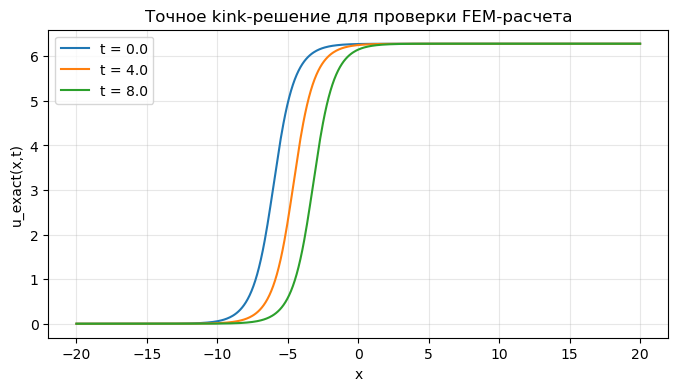

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

# Базовые параметры теста. Область берем широкой, чтобы солитон не успел быстро упереться в границу.
x_left, x_right = -20.0, 20.0
x0 = -6.0
velocity = 0.35
T = 8.0

def kink_exact_np(x, t, x0=x0, v=velocity):
    """Точное kink-решение уравнения Синус-Гордона для numpy-массивов."""
    gamma = math.sqrt(1.0 - v**2)
    return 4.0 * np.arctan(np.exp((x - x0 - v * t) / gamma))

xs = np.linspace(x_left, x_right, 600)
plt.figure(figsize=(8, 4))
for t in [0.0, T / 2, T]:
    plt.plot(xs, kink_exact_np(xs, t), label=f"t = {t:.1f}")
plt.xlabel("x")
plt.ylabel("u_exact(x,t)")
plt.title("Точное kink-решение для проверки FEM-расчета")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 2. Слабая форма и схема по времени

Ищем $u^{n+1}$ по известным $u^n$ и $u^{n-1}$. Используем неявную схему второго порядка:

$$
    \frac{u^{n+1}-2u^n+u^{n-1}}{\Delta t^2}
    - u^{n+1}_{xx}
    + \sin(u^{n+1}) = 0.
$$

Домножаем на тестовую функцию $\varphi$, зануляющуюся на границе, интегрируем по области и переносим вторую производную по частям:

$$
    \int_\Omega
    \frac{u^{n+1}-2u^n+u^{n-1}}{\Delta t^2}\varphi\,dx
    + \int_\Omega \nabla u^{n+1}\cdot\nabla\varphi\,dx
    + \int_\Omega \sin(u^{n+1})\varphi\,dx
    = 0.
$$

Это нелинейное уравнение относительно $u^{n+1}$ из-за $\sin(u^{n+1})$. В коде ниже это будет residual `F`; FEniCS сам построит якобиан через `derivative(F, u)` и применит метод Ньютона.

In [2]:
# Эта ячейка рассчитана на окружение с FEniCS legacy/dolfin.
# Локально в текущем shell FEniCS может быть не установлен, но kernel ноутбука уже назван fenics-legacy.
try:
    import fenics as fe
except ImportError:
    import dolfin as fe

N_elements = 200
dt = 0.02
n_steps = int(T / dt)

mesh = fe.IntervalMesh(N_elements, x_left, x_right)
V = fe.FunctionSpace(mesh, "Lagrange", 1)

class KinkExact(fe.UserExpression):
    def __init__(self, t=0.0, x0=x0, v=velocity, **kwargs):
        super().__init__(**kwargs)
        self.t = t
        self.x0 = x0
        self.v = v

    def eval(self, values, x):
        gamma = math.sqrt(1.0 - self.v**2)
        values[0] = 4.0 * math.atan(math.exp((x[0] - self.x0 - self.v * self.t) / gamma))

    def value_shape(self):
        return ()

def boundary(x, on_boundary):
    return on_boundary

u_exact = KinkExact(t=0.0, degree=4)
bc = fe.DirichletBC(V, u_exact, boundary)

u_nm1 = fe.interpolate(KinkExact(t=-dt, degree=4), V)
u_n = fe.interpolate(KinkExact(t=0.0, degree=4), V)
u = fe.Function(V)
phi = fe.TestFunction(V)

F = (
    ((u - 2.0 * u_n + u_nm1) / dt**2) * phi * fe.dx
    + fe.dot(fe.grad(u), fe.grad(phi)) * fe.dx
    + fe.sin(u) * phi * fe.dx
)
J = fe.derivative(F, u)

print("Слабая форма собрана. Следующий шаг: временной цикл, L2-ошибка и энергия.")

Слабая форма собрана. Следующий шаг: временной цикл, L2-ошибка и энергия.


In [3]:
# Черновик следующего шага: один временной шаг с Newton solver.
# После проверки постановки расширим это до функции solve_sine_gordon(...).

time = 0.0
u.assign(u_n)  # начальное приближение для Ньютона: решение с предыдущего слоя

u_exact.t = time + dt
fe.solve(
    F == 0,
    u,
    bc,
    J=J,
    solver_parameters={
        "newton_solver": {
            "absolute_tolerance": 1e-10,
            "relative_tolerance": 1e-9,
            "maximum_iterations": 25,
        }
    },
)

l2_error = fe.errornorm(u_exact, u, norm_type="L2", degree_rise=3)
print(f"После одного шага t={time + dt:.3f}: L2 error = {l2_error:.3e}")

После одного шага t=0.020: L2 error = 6.568e-03Solving nonlinear variational problem.
  Newton iteration 0: r (abs) = 2.281e+01 (tol = 1.000e-10) r (rel) = 1.000e+00 (tol = 1.000e-09)
  Newton iteration 1: r (abs) = 3.699e-05 (tol = 1.000e-10) r (rel) = 1.622e-06 (tol = 1.000e-09)
  Newton iteration 2: r (abs) = 1.421e-12 (tol = 1.000e-10) r (rel) = 6.228e-14 (tol = 1.000e-09)
  Newton solver finished in 2 iterations and 2 linear solver iterations.



## 3. Полный временной расчет

Один шаг уже прошел: Newton solver сошелся за 2 итерации, значит слабая форма и граничные условия согласованы. Теперь оборачиваем тот же шаг в функцию, которая возвращает историю ошибки, энергии и несколько снимков решения.

Численная энергия для контроля:

$$
    E_h^n = \int_\Omega \left[
        \frac12 \left(\frac{u^n-u^{n-1}}{\Delta t}\right)^2
        + \frac12 |\nabla u^n|^2
        + 1 - \cos(u^n)
    \right] dx.
$$

Это не строго сохраняемая энергия конкретной временной схемы, но ее дрейф хорошо показывает, не начинает ли расчет искусственно разгоняться или чрезмерно затухать.

In [4]:
try:
    fe
except NameError:
    try:
        import fenics as fe
    except ImportError:
        import dolfin as fe


def set_fenics_quiet():
    """Уменьшаем служебный вывод FEniCS, чтобы временной цикл не засорял ноутбук."""
    try:
        fe.set_log_level(fe.LogLevel.WARNING)
    except Exception:
        try:
            fe.set_log_level(30)
        except Exception:
            pass


def function_to_arrays(function, space):
    coords = space.tabulate_dof_coordinates().reshape((-1, 1))[:, 0]
    values = function.vector().get_local()
    order = np.argsort(coords)
    return coords[order], values[order]


def discrete_energy(u_new, u_old, dt):
    u_t = (u_new - u_old) / dt
    density = 0.5 * u_t**2 + 0.5 * fe.dot(fe.grad(u_new), fe.grad(u_new)) + 1.0 - fe.cos(u_new)
    return float(fe.assemble(density * fe.dx))


def solve_sine_gordon(
    N_elements=200,
    dt=0.02,
    T=8.0,
    x_left=x_left,
    x_right=x_right,
    x0=x0,
    v=velocity,
    snapshot_times=None,
    verbose=False,
):
    """Решает 1D уравнение Синус-Гордона и сравнивает FEM-решение с kink-решением."""
    if snapshot_times is None:
        snapshot_times = [0.0, T / 2.0, T]

    set_fenics_quiet()

    n_steps = int(round(T / dt))
    actual_T = n_steps * dt
    mesh = fe.IntervalMesh(N_elements, x_left, x_right)
    V = fe.FunctionSpace(mesh, "Lagrange", 1)

    exact = KinkExact(t=0.0, x0=x0, v=v, degree=4)
    bc = fe.DirichletBC(V, exact, boundary)

    u_nm1 = fe.interpolate(KinkExact(t=-dt, x0=x0, v=v, degree=4), V)
    u_n = fe.interpolate(KinkExact(t=0.0, x0=x0, v=v, degree=4), V)
    u = fe.Function(V)
    phi = fe.TestFunction(V)

    F = (
        ((u - 2.0 * u_n + u_nm1) / dt**2) * phi * fe.dx
        + fe.dot(fe.grad(u), fe.grad(phi)) * fe.dx
        + fe.sin(u) * phi * fe.dx
    )
    J = fe.derivative(F, u)

    solver_parameters = {
        "newton_solver": {
            "absolute_tolerance": 1e-10,
            "relative_tolerance": 1e-9,
            "maximum_iterations": 25,
            "report": verbose,
            "error_on_nonconvergence": True,
        }
    }

    times = [0.0]
    errors = [fe.errornorm(exact, u_n, norm_type="L2", degree_rise=3)]
    energies = [discrete_energy(u_n, u_nm1, dt)]
    snapshots = {}

    def save_snapshot_if_needed(time_value, function):
        if not snapshot_times:
            return
        target = min(snapshot_times, key=lambda item: abs(item - time_value))
        if abs(target - time_value) <= 0.5 * dt + 1e-14:
            snapshots[float(target)] = function_to_arrays(function, V)

    save_snapshot_if_needed(0.0, u_n)

    for step in range(1, n_steps + 1):
        time_value = step * dt
        exact.t = time_value
        u.assign(u_n)

        fe.solve(F == 0, u, bc, J=J, solver_parameters=solver_parameters)

        times.append(time_value)
        errors.append(fe.errornorm(exact, u, norm_type="L2", degree_rise=3))
        energies.append(discrete_energy(u, u_n, dt))
        save_snapshot_if_needed(time_value, u)

        u_nm1.assign(u_n)
        u_n.assign(u)

        if verbose and (step == 1 or step == n_steps or step % max(1, n_steps // 10) == 0):
            print(f"step {step:4d}/{n_steps}, t={time_value:.3f}, L2={errors[-1]:.3e}")

    final_x, final_u = function_to_arrays(u_n, V)
    return {
        "times": np.array(times),
        "errors": np.array(errors),
        "energies": np.array(energies),
        "snapshots": snapshots,
        "final_x": final_x,
        "final_u": final_u,
        "h": (x_right - x_left) / N_elements,
        "N": N_elements,
        "dt": dt,
        "T": actual_T,
    }

print("Функции для полного расчета готовы.")

Функции для полного расчета готовы.


N = 200, h = 0.2000, dt = 0.0200, T = 8.00
Начальная L2-ошибка интерполяции: 6.568e-03
Финальная L2-ошибка: 2.993e-02
Максимальный относительный дрейф энергии: 8.866e-04


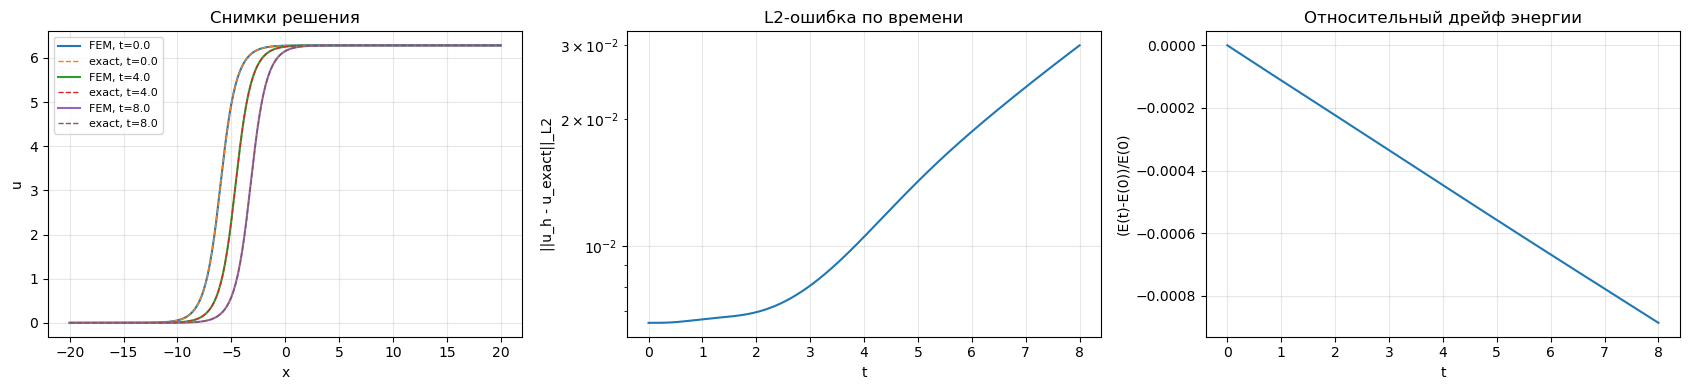

In [5]:
result = solve_sine_gordon(
    N_elements=200,
    dt=0.02,
    T=T,
    snapshot_times=[0.0, T / 2.0, T],
    verbose=False,
)

energy0 = result["energies"][0]
relative_energy_drift = (result["energies"] - energy0) / abs(energy0)

print(f"N = {result['N']}, h = {result['h']:.4f}, dt = {result['dt']:.4f}, T = {result['T']:.2f}")
print(f"Начальная L2-ошибка интерполяции: {result['errors'][0]:.3e}")
print(f"Финальная L2-ошибка: {result['errors'][-1]:.3e}")
print(f"Максимальный относительный дрейф энергии: {np.max(np.abs(relative_energy_drift)):.3e}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for time_value, (x_values, u_values) in sorted(result["snapshots"].items()):
    axes[0].plot(x_values, u_values, label=f"FEM, t={time_value:.1f}")
    axes[0].plot(
        x_values,
        kink_exact_np(x_values, time_value),
        "--",
        linewidth=1,
        label=f"exact, t={time_value:.1f}",
    )
axes[0].set_title("Снимки решения")
axes[0].set_xlabel("x")
axes[0].set_ylabel("u")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].semilogy(result["times"], result["errors"])
axes[1].set_title("L2-ошибка по времени")
axes[1].set_xlabel("t")
axes[1].set_ylabel("||u_h - u_exact||_L2")
axes[1].grid(alpha=0.3)

axes[2].plot(result["times"], relative_energy_drift)
axes[2].set_title("Относительный дрейф энергии")
axes[2].set_xlabel("t")
axes[2].set_ylabel("(E(t)-E(0))/E(0)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Исследование сходимости по пространству

Для оценки скорости сходимости фиксируем маленький шаг по времени и меняем только размер сетки. В идеале для линейных элементов `Lagrange P1` ожидаем порядок около $O(h^2)$ в $L_2$-норме, пока ошибка по времени не начинает доминировать.

Если расчет ниже идет долго, сначала оставляем `N_values = [50, 100, 200]`. Для более убедительного графика можно добавить `400`.

N=  50, h=0.80000, final L2 error=9.942e-02
N= 100, h=0.40000, final L2 error=2.572e-02
N= 200, h=0.20000, final L2 error=6.528e-03

Таблица сходимости
       N            h       L2 error       rate
      50      0.80000      9.942e-02          -
     100      0.40000      2.572e-02       1.95
     200      0.20000      6.528e-03       1.98


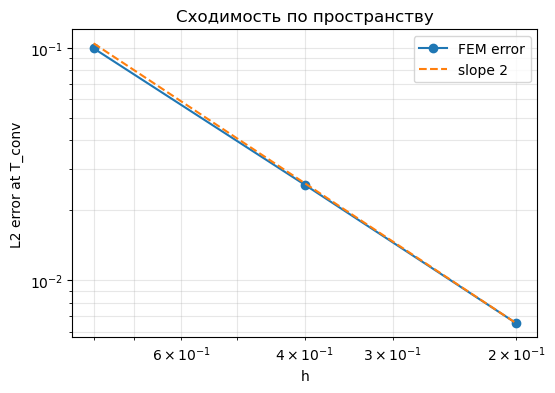

In [6]:
def mesh_convergence_study(N_values=(50, 100, 200), dt_conv=0.005, T_conv=1.0):
    rows = []
    for N in N_values:
        current = solve_sine_gordon(
            N_elements=N,
            dt=dt_conv,
            T=T_conv,
            snapshot_times=[T_conv],
            verbose=False,
        )
        rows.append({
            "N": N,
            "h": current["h"],
            "error": current["errors"][-1],
        })
        print(f"N={N:4d}, h={current['h']:.5f}, final L2 error={current['errors'][-1]:.3e}")

    for i, row in enumerate(rows):
        if i == 0:
            row["rate"] = np.nan
        else:
            prev = rows[i - 1]
            row["rate"] = np.log(prev["error"] / row["error"]) / np.log(prev["h"] / row["h"])
    return rows


N_values = [50, 100, 200]
conv_rows = mesh_convergence_study(N_values=N_values, dt_conv=0.005, T_conv=1.0)

print("\nТаблица сходимости")
print(f"{'N':>8} {'h':>12} {'L2 error':>14} {'rate':>10}")
for row in conv_rows:
    rate_text = "-" if np.isnan(row["rate"]) else f"{row['rate']:.2f}"
    print(f"{row['N']:8d} {row['h']:12.5f} {row['error']:14.3e} {rate_text:>10}")

hs = np.array([row["h"] for row in conv_rows])
errors = np.array([row["error"] for row in conv_rows])

plt.figure(figsize=(6, 4))
plt.loglog(hs, errors, "o-", label="FEM error")
plt.loglog(hs, errors[-1] * (hs / hs[-1])**2, "--", label="slope 2")
plt.gca().invert_xaxis()
plt.xlabel("h")
plt.ylabel("L2 error at T_conv")
plt.title("Сходимость по пространству")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

## 5. Численные результаты

Полный временной расчет для сетки `N = 200` дал:

| параметр | значение |
|---:|---:|
| $h$ | 0.2000 |
| $\Delta t$ | 0.0200 |
| $T$ | 8.00 |
| начальная $L_2$-ошибка интерполяции | $6.568\cdot 10^{-3}$ |
| финальная $L_2$-ошибка | $2.993\cdot 10^{-2}$ |
| максимальный относительный дрейф энергии | $8.866\cdot 10^{-4}$ |

Малый дрейф энергии показывает, что за выбранное время расчет не разгоняется и не затухает численно слишком сильно.

По сохраненному запуску исследования сходимости получилась таблица:

| $N$ | $h$ | $L_2$-ошибка | порядок |
|---:|---:|---:|---:|
| 50 | 0.80000 | $9.942\cdot 10^{-2}$ | - |
| 100 | 0.40000 | $2.572\cdot 10^{-2}$ | 1.95 |
| 200 | 0.20000 | $6.528\cdot 10^{-3}$ | 1.98 |

Итог: при уменьшении шага сетки в 2 раза ошибка уменьшается примерно в 4 раза. Значит, в $L_2$-норме наблюдается скорость сходимости около

$$
    \|u_h-u\|_{L_2} = O(h^2),
$$

что согласуется с ожидаемым поведением линейных конечных элементов `Lagrange P1`, если шаг по времени выбран достаточно малым и не доминирует в общей ошибке.

## 6. С какими проблемами столкнулись

1. **Бесконечная область заменяется конечным отрезком.** Точное kink-решение задано на всей прямой, а FEM-расчет идет на $[x_L,x_R]$. Поэтому область нужно брать достаточно широкой или задавать граничные условия из точного решения. Иначе солитон дойдет до границы, отразится или исказится.

2. **Ошибки по пространству и времени смешиваются.** Для проверки FEM-сходимости нужно уменьшать $h$, но при слишком большом $\Delta t$ график ошибки перестанет показывать пространственный порядок. Поэтому в исследовании сходимости использован малый шаг `dt_conv = 0.005` и небольшой интервал времени `T_conv = 1.0`.

3. **Нелинейность требует итерационного решения.** Из-за слагаемого $\sin(u^{n+1})$ на каждом временном слое решается нелинейная задача методом Ньютона. В первом тесте метод Ньютона сошелся за 2 итерации, что подтверждает корректность начального приближения `u.assign(u_n)`.

4. **Быстрый солитон сложнее разрешать сеткой.** В точном решении ширина фронта пропорциональна $\sqrt{1-v^2}$. При $v\to 1$ фронт становится крутым, и на фиксированной сетке ошибка должна заметно расти. Это хороший дополнительный эксперимент, если нужно расширить исследование.

## 7. Итог по заданию

В работе решено нелинейное гиперболическое УРЧП, которого не было среди базовых примеров PDF:

$$
    u_{tt} - u_{xx} + \sin u = 0.
$$

Пространственная часть аппроксимирована методом конечных элементов в FEniCS на элементах `Lagrange P1`, время дискретизовано вручную неявной схемой второго порядка. Корректность проверялась сравнением с точным солитонным kink-решением и контролем энергии.

Требования из PDF закрыты:

1. **Придумать УРЧП не из рассмотренных примеров:** выбрано уравнение Синус-Гордона.
2. **Решить его с помощью FEniCS и FEM:** реализованы слабая форма, временной цикл, Newton solver и графики решения.
3. **Описать проблемы:** перечислены граничные эффекты, смешивание временной и пространственной ошибок, нелинейный решатель и сложность резкого фронта.
4. **Найти скорость сходимости к истинному решению:** по таблице получен порядок $1.95$-$1.98$, то есть практически $O(h^2)$ в $L_2$-норме.